In [1]:
import pandas as pd
import glob

files = glob.glob("../data/VCDB/data/csv/*.csv")
print(files)

df = pd.read_csv(files[0], low_memory=False)
print(df.shape)
print(list(df.columns)[:60])

[]


IndexError: list index out of range

In [2]:
import pandas as pd

df = pd.read_csv("../data/vcdb_csv/vcdb.csv", low_memory=False)
print(df.shape)
print(list(df.columns)[:80])

(10596, 2683)
['action.environmental.notes', 'action.environmental.variety.Deterioration', 'action.environmental.variety.Earthquake', 'action.environmental.variety.EMI', 'action.environmental.variety.ESD', 'action.environmental.variety.Fire', 'action.environmental.variety.Flood', 'action.environmental.variety.Hazmat', 'action.environmental.variety.Humidity', 'action.environmental.variety.Hurricane', 'action.environmental.variety.Ice', 'action.environmental.variety.Landslide', 'action.environmental.variety.Leak', 'action.environmental.variety.Lightning', 'action.environmental.variety.Meteorite', 'action.environmental.variety.Other', 'action.environmental.variety.Particulates', 'action.environmental.variety.Pathogen', 'action.environmental.variety.Power failure', 'action.environmental.variety.Temperature', 'action.environmental.variety.Tornado', 'action.environmental.variety.Tsunami', 'action.environmental.variety.Unknown', 'action.environmental.variety.Vermin', 'action.environmental.var

In [3]:
groups = ["action", "actor", "asset", "attribute", "victim", "timeline", "impact", "discovery", "incident_id", "summary"]
for g in groups:
    cols = [c for c in df.columns if c.startswith(g)]
    print(g, len(cols))

print([c for c in df.columns if c.startswith("victim")][:40])
print([c for c in df.columns if c.startswith("impact")][:40])
print([c for c in df.columns if c.startswith("timeline")])

action 347
actor 595
asset 494
attribute 105
victim 483
timeline 48
impact 196
discovery 43
incident_id 1
summary 1
['victim.country.AD', 'victim.country.AE', 'victim.country.AF', 'victim.country.AG', 'victim.country.AI', 'victim.country.AL', 'victim.country.AM', 'victim.country.AO', 'victim.country.AQ', 'victim.country.AR', 'victim.country.AS', 'victim.country.AT', 'victim.country.AU', 'victim.country.AW', 'victim.country.AX', 'victim.country.AZ', 'victim.country.BA', 'victim.country.BB', 'victim.country.BD', 'victim.country.BE', 'victim.country.BF', 'victim.country.BG', 'victim.country.BH', 'victim.country.BI', 'victim.country.BJ', 'victim.country.BL', 'victim.country.BM', 'victim.country.BN', 'victim.country.BO', 'victim.country.BQ', 'victim.country.BR', 'victim.country.BS', 'victim.country.BT', 'victim.country.BV', 'victim.country.BW', 'victim.country.BY', 'victim.country.BZ', 'victim.country.CA', 'victim.country.CC', 'victim.country.CD']
['impact.iso_currency_code.AED', 'impact.is

In [4]:
def show(prefix, n=60):
    cols = [c for c in df.columns if c.startswith(prefix)]
    print(prefix, len(cols))
    print(cols[:n], "\n")

show("victim.employee_count")
show("victim.revenue")
show("victim.industry", 15)
show("impact.overall_amount")
show("impact.overall_rating")
show("impact.loss")
show("action.malware.variety", 12)
show("action.social.variety", 12)
show("action.hacking.vector", 12)

print(df["timeline.incident.year"].value_counts().sort_index().tail(15))

victim.employee_count 11
['victim.employee_count.1 to 10', 'victim.employee_count.10001 to 25000', 'victim.employee_count.1001 to 10000', 'victim.employee_count.101 to 1000', 'victim.employee_count.11 to 100', 'victim.employee_count.25001 to 50000', 'victim.employee_count.50001 to 100000', 'victim.employee_count.Large', 'victim.employee_count.Over 100000', 'victim.employee_count.Small', 'victim.employee_count.Unknown'] 

victim.revenue 171
['victim.revenue.amount', 'victim.revenue.iso_currency_code.AED', 'victim.revenue.iso_currency_code.AFN', 'victim.revenue.iso_currency_code.ALL', 'victim.revenue.iso_currency_code.AMD', 'victim.revenue.iso_currency_code.ANG', 'victim.revenue.iso_currency_code.AOA', 'victim.revenue.iso_currency_code.ARS', 'victim.revenue.iso_currency_code.AUD', 'victim.revenue.iso_currency_code.AWG', 'victim.revenue.iso_currency_code.AZN', 'victim.revenue.iso_currency_code.BAM', 'victim.revenue.iso_currency_code.BBD', 'victim.revenue.iso_currency_code.BCH', 'victim.re

In [5]:
def collapse(prefix):
    cols = [c for c in df.columns if c.startswith(prefix)]
    sub = df[cols].fillna(False).astype(bool)
    out = sub.idxmax(axis=1).str.replace(prefix, "", regex=False)
    out[~sub.any(axis=1)] = "Unknown"
    return out

clean = pd.DataFrame()
clean["incident_id"] = df["incident_id"]
clean["year"] = df["timeline.incident.year"]
clean["industry"] = df["victim.industry2"]
clean["size"] = collapse("victim.employee_count.")

for a in ["hacking", "malware", "social", "error", "misuse", "physical", "environmental"]:
    cols = [c for c in df.columns if c.startswith(f"action.{a}.variety")]
    clean[a] = df[cols].fillna(False).astype(bool).any(axis=1)

clean["loss_amount"] = df["impact.loss.amount"]
clean["overall_amount"] = df["impact.overall_amount"]

clean.to_csv("../data/vcdb_clean.csv", index=False)

print(clean.shape)
print(clean["size"].value_counts())
print(clean["industry"].value_counts().head(10))
print(clean[["hacking","malware","social","error","misuse","physical","environmental"]].mean().round(3))
print(clean[["loss_amount","overall_amount"]].notna().sum())

(10596, 13)
size
Unknown            2879
1001 to 10000      1486
101 to 1000        1293
Over 100000        1133
Large               990
11 to 100           920
10001 to 25000      511
Small               479
1 to 10             464
25001 to 50000      264
50001 to 100000     177
Name: count, dtype: int64
industry
62    2564
92    2403
61    1155
52     980
51     876
54     488
44     405
0      223
81     218
56     196
Name: count, dtype: int64
hacking          0.343
malware          0.167
social           0.064
error            0.262
misuse           0.173
physical         0.162
environmental    0.001
dtype: float64
loss_amount         0
overall_amount    337
dtype: int64


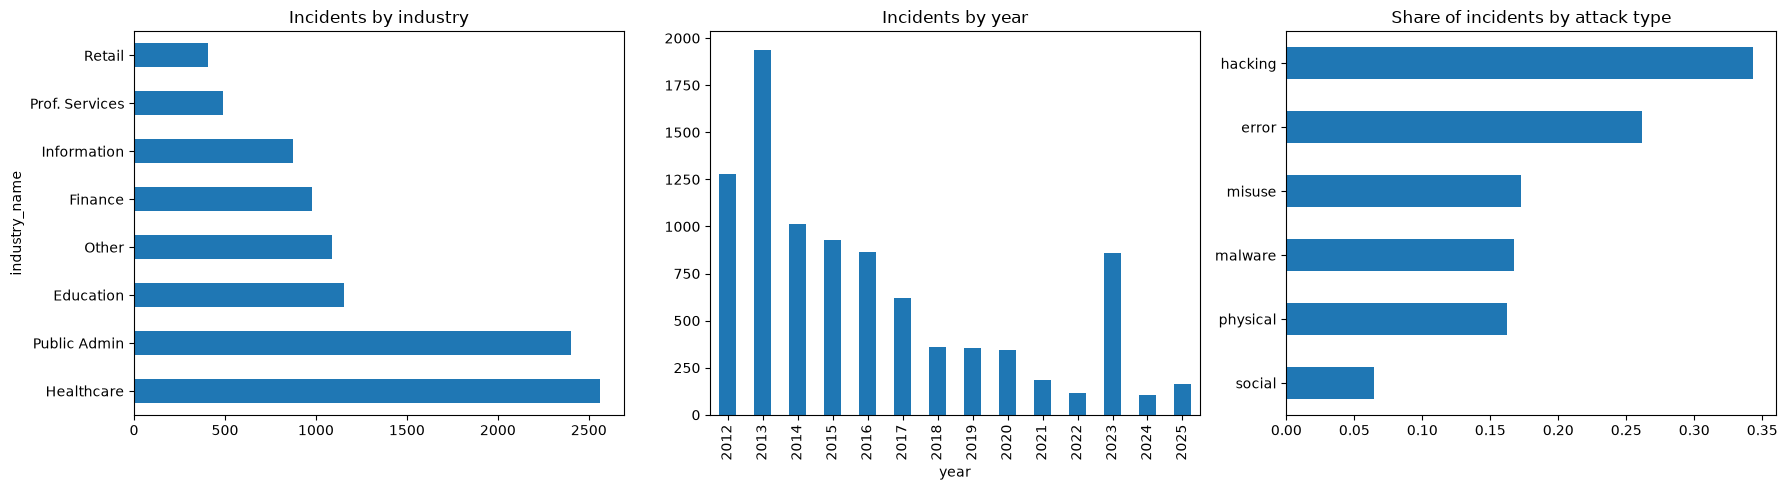

In [7]:
import matplotlib.pyplot as plt

naics = {"62":"Healthcare","92":"Public Admin","61":"Education","52":"Finance","51":"Information",
         "54":"Prof. Services","44":"Retail","81":"Other Services","56":"Admin/Support","0":"Unknown"}

clean["industry_name"] = clean["industry"].astype(str).map(naics).fillna("Other")

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

clean["industry_name"].value_counts().head(8).plot(kind="barh", ax=ax[0], title="Incidents by industry")
clean[clean["year"].between(2012, 2025)]["year"].value_counts().sort_index().plot(kind="bar", ax=ax[1], title="Incidents by year")
clean[["hacking","malware","social","error","misuse","physical"]].mean().sort_values().plot(kind="barh", ax=ax[2], title="Share of incidents by attack type")

plt.tight_layout()
plt.savefig("../docs/eda_overview.png", dpi=150)
plt.show()